In [1]:

# TASK 1: Import Libraries and Load Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("fake_job_postings.csv")

# Display basic information
print("Dataset loaded successfully!")
print("\nDataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset loaded successfully!

Dataset Shape: (17880, 18)

First 5 Records:


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0



Column Names:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non

Missing Values in Each Column:


job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64


Duplicate Rows: 0

Column Data Types:


job_id                  int64
title                  object
location               object
department             object
salary_range           object
company_profile        object
description            object
requirements           object
benefits               object
telecommuting           int64
has_company_logo        int64
has_questions           int64
employment_type        object
required_experience    object
required_education     object
industry               object
function               object
fraudulent              int64
dtype: object


Unique Values in Each Column:


job_id                 17880
title                  11231
location                3105
department              1337
salary_range             874
company_profile         1709
description            14801
requirements           11967
benefits                6204
telecommuting              2
has_company_logo           2
has_questions              2
employment_type            5
required_experience        7
required_education        13
industry                 131
function                  37
fraudulent                 2
dtype: int64

... (2 outputs left out)


Job Posting Distribution:


fraudulent
0    17014
1      866
Name: count, dtype: int64


Job Posting Percentages:


fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64

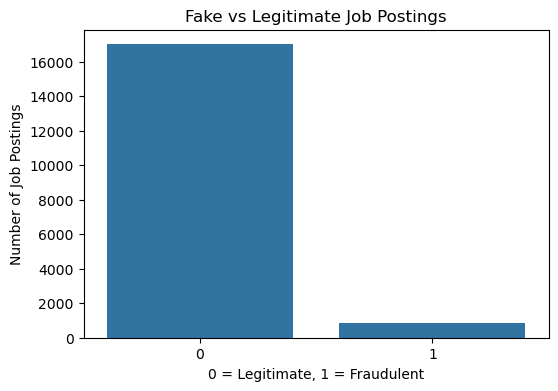


Dataset inspection completed successfully!


In [2]:

# TASK 2: Basic Dataset Inspection

# Check missing values
print("Missing Values in Each Column:")
display(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Check data types
print("\nColumn Data Types:")
display(df.dtypes)

# Check unique values
print("\nUnique Values in Each Column:")
display(df.nunique())

# Statistical summary
print("\nDataset Statistical Summary:")
display(df.describe(include="all").T)

# Check fraudulent and legitimate job counts
print("\nJob Posting Distribution:")
display(df["fraudulent"].value_counts())

# Calculate percentages
print("\nJob Posting Percentages:")
display(
    (df["fraudulent"].value_counts(normalize=True) * 100).round(2)
)

# Visualize job distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="fraudulent")
plt.title("Fake vs Legitimate Job Postings")
plt.xlabel("0 = Legitimate, 1 = Fraudulent")
plt.ylabel("Number of Job Postings")
plt.show()

print("\nDataset inspection completed successfully!")


In [3]:

# TASK 3: Data Cleaning and Preprocessing

# 1. Check dataset before cleaning
print("Dataset shape before cleaning:", df.shape)

# 2. Remove duplicate records
df = df.drop_duplicates().copy()

# 3. Handle missing text values
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

for col in text_columns:
    df[col] = df[col].fillna("")

# 4. Handle missing categorical values
categorical_columns = [
    "location",
    "department",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

for col in categorical_columns:
    df[col] = df[col].fillna("Unknown")

# 5. Handle missing salary range
df["salary_range"] = df["salary_range"].fillna("Not Specified")

# 6. Handle missing binary values
binary_columns = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

for col in binary_columns:
    df[col] = df[col].fillna(0)

# 7. Remove job_id because it is only an identifier
df = df.drop(columns=["job_id"])

# 8. Check missing values after cleaning
print("\nMissing values after cleaning:")
display(df.isnull().sum())

# 9. Check final dataset shape
print("\nDataset shape after cleaning:", df.shape)

# 10. Check target distribution
print("\nFraudulent job distribution:")
display(df["fraudulent"].value_counts())

print("\nData cleaning completed successfully!")


Dataset shape before cleaning: (17880, 18)

Missing values after cleaning:


title                  0
location               0
department             0
salary_range           0
company_profile        0
description            0
requirements           0
benefits               0
telecommuting          0
has_company_logo       0
has_questions          0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
fraudulent             0
dtype: int64


Dataset shape after cleaning: (17880, 17)

Fraudulent job distribution:


fraudulent
0    17014
1      866
Name: count, dtype: int64


Data cleaning completed successfully!


In [4]:

# TASK 4: Text Cleaning

import re
import string

# Function to clean text
def clean_text(text):
    text = str(text)

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Combine important text columns
df["combined_text"] = (
    df["title"] + " " +
    df["company_profile"] + " " +
    df["description"] + " " +
    df["requirements"] + " " +
    df["benefits"]
)

# Apply text cleaning
df["cleaned_text"] = df["combined_text"].apply(clean_text)

# Display original and cleaned text
print("Original Job Description:")
display(df["combined_text"].head(3))

print("\nCleaned Job Description:")
display(df["cleaned_text"].head(3))

# Check empty text records
print("\nEmpty cleaned text records:",
      (df["cleaned_text"].str.len() == 0).sum())

print("\nText cleaning completed successfully!")


Original Job Description:


0    Marketing Intern We're Food52, and we've creat...
1    Customer Service - Cloud Video Production 90 S...
2    Commissioning Machinery Assistant (CMA) Valor ...
Name: combined_text, dtype: object


Cleaned Job Description:


0    marketing intern we re food and we ve created ...
1    customer service cloud video production second...
2    commissioning machinery assistant cma valor se...
Name: cleaned_text, dtype: object


Empty cleaned text records: 0

Text cleaning completed successfully!


Job Posting Distribution:


fraudulent
Legitimate    17014
Fraudulent      866
Name: count, dtype: int64

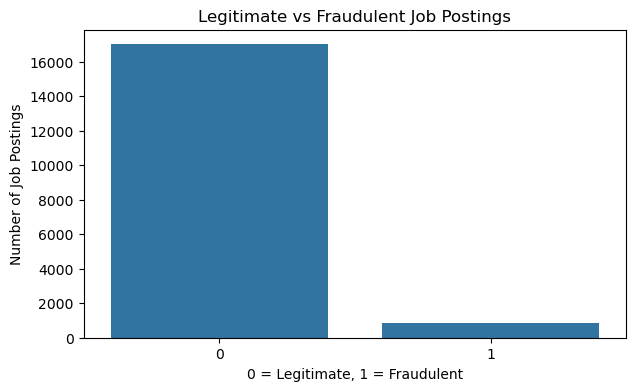

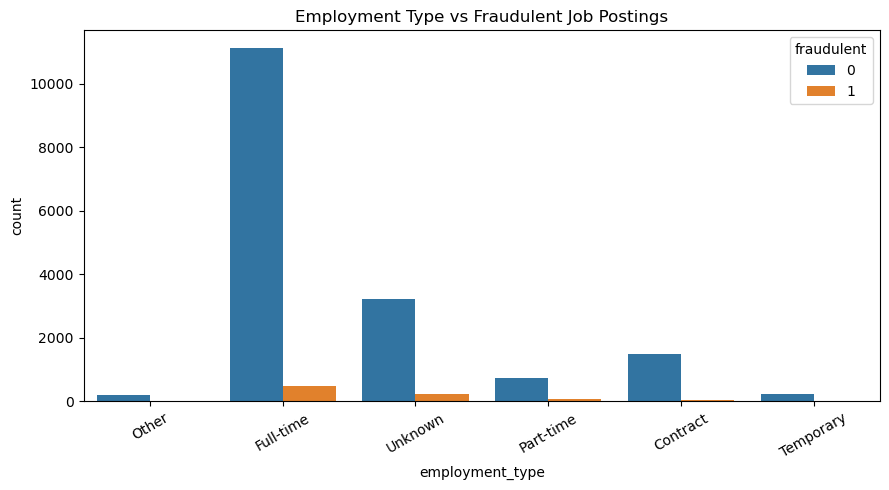

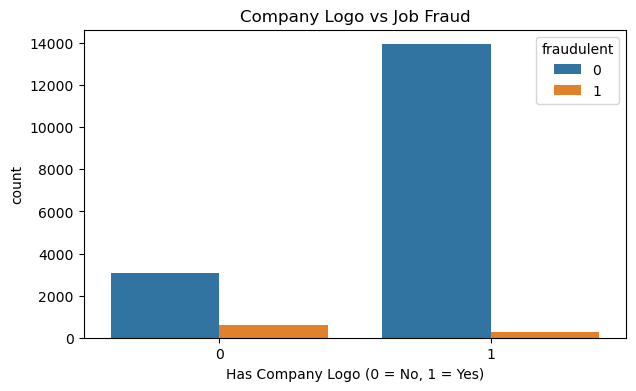

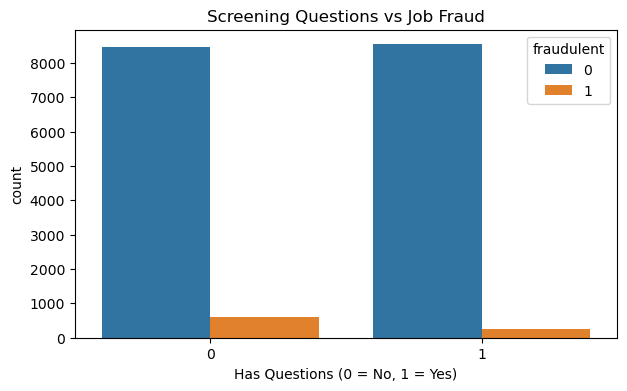


Average Description Length:


,description_length,company_profile_length
fraudulent,,
0,1221.22,640.75
1,1154.83,230.89


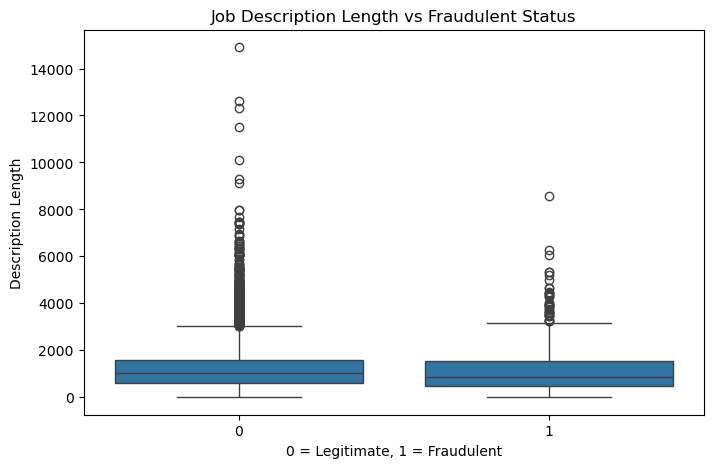


EDA completed successfully!


In [5]:

# TASK 5: Exploratory Data Analysis

# 1. Count legitimate and fraudulent job postings
print("Job Posting Distribution:")
display(df["fraudulent"].value_counts().rename({
    0: "Legitimate",
    1: "Fraudulent"
}))

# 2. Visualize job posting distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="fraudulent")
plt.title("Legitimate vs Fraudulent Job Postings")
plt.xlabel("0 = Legitimate, 1 = Fraudulent")
plt.ylabel("Number of Job Postings")
plt.show()

# 3. Analyze employment types
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="employment_type",
    hue="fraudulent"
)
plt.title("Employment Type vs Fraudulent Job Postings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 4. Analyze company logo availability
plt.figure(figsize=(7, 4))
sns.countplot(
    data=df,
    x="has_company_logo",
    hue="fraudulent"
)
plt.title("Company Logo vs Job Fraud")
plt.xlabel("Has Company Logo (0 = No, 1 = Yes)")
plt.show()

# 5. Analyze questions availability
plt.figure(figsize=(7, 4))
sns.countplot(
    data=df,
    x="has_questions",
    hue="fraudulent"
)
plt.title("Screening Questions vs Job Fraud")
plt.xlabel("Has Questions (0 = No, 1 = Yes)")
plt.show()

# 6. Average text length comparison
df["description_length"] = df["description"].str.len()
df["company_profile_length"] = df["company_profile"].str.len()

print("\nAverage Description Length:")
display(
    df.groupby("fraudulent")[
        ["description_length", "company_profile_length"]
    ].mean().round(2)
)

# 7. Visualize description length
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="fraudulent",
    y="description_length"
)
plt.title("Job Description Length vs Fraudulent Status")
plt.xlabel("0 = Legitimate, 1 = Fraudulent")
plt.ylabel("Description Length")
plt.show()

print("\nEDA completed successfully!")


In [6]:

# TASK 6: TF-IDF Text Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2)
)

# Convert cleaned text into numerical features
X_text = tfidf.fit_transform(df["cleaned_text"])

# Target variable
y = df["fraudulent"]

# Display results
print("TF-IDF Vectorization completed!")
print("\nOriginal Text Shape:", df["cleaned_text"].shape)
print("TF-IDF Matrix Shape:", X_text.shape)

print("\nTotal vocabulary words:", len(tfidf.vocabulary_))

print("\nSample vocabulary words:")
print(list(tfidf.vocabulary_.keys())[:20])

print("\nTarget Variable Shape:", y.shape)


TF-IDF Vectorization completed!

Original Text Shape: (17880,)
TF-IDF Matrix Shape: (17880, 5000)

Total vocabulary words: 5000

Sample vocabulary words:
['marketing', 'intern', 'food', 've', 'created', 'award', 'winning', 'cooking', 'site', 'support', 'connect', 'home', 'need', 'place', 'editorial', 'business', 'engineering', 'team', 'focused', 'using']

Target Variable Shape: (17880,)


In [7]:

# TASK 7: Train-Test Split

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train-Test Split Completed!")

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
display(y_train.value_counts())

print("\nTesting Target Distribution:")
display(y_test.value_counts())


Train-Test Split Completed!

Training Data Shape: (14304, 5000)
Testing Data Shape: (3576, 5000)

Training Target Distribution:


fraudulent
0    13611
1      693
Name: count, dtype: int64


Testing Target Distribution:


fraudulent
0    3403
1     173
Name: count, dtype: int64


Training Logistic Regression...
Logistic Regression completed!

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3403
           1       0.66      0.90      0.76       173

    accuracy                           0.97      3576
   macro avg       0.83      0.94      0.87      3576
weighted avg       0.98      0.97      0.97      3576


Training Naive Bayes...
Naive Bayes completed!

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3403
           1       0.91      0.42      0.58       173

    accuracy                           0.97      3576
   macro avg       0.94      0.71      0.78      3576
weighted avg       0.97      0.97      0.96      3576


Training Random Forest...
Random Forest completed!

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3403
 

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.9810,0.7838,0.8382,0.8101
1,Logistic Regression,0.9729,0.6610,0.9017,0.7628
2,Random Forest,0.9787,1.0000,0.5607,0.7185
3,Naive Bayes,0.9701,0.9125,0.4220,0.5771


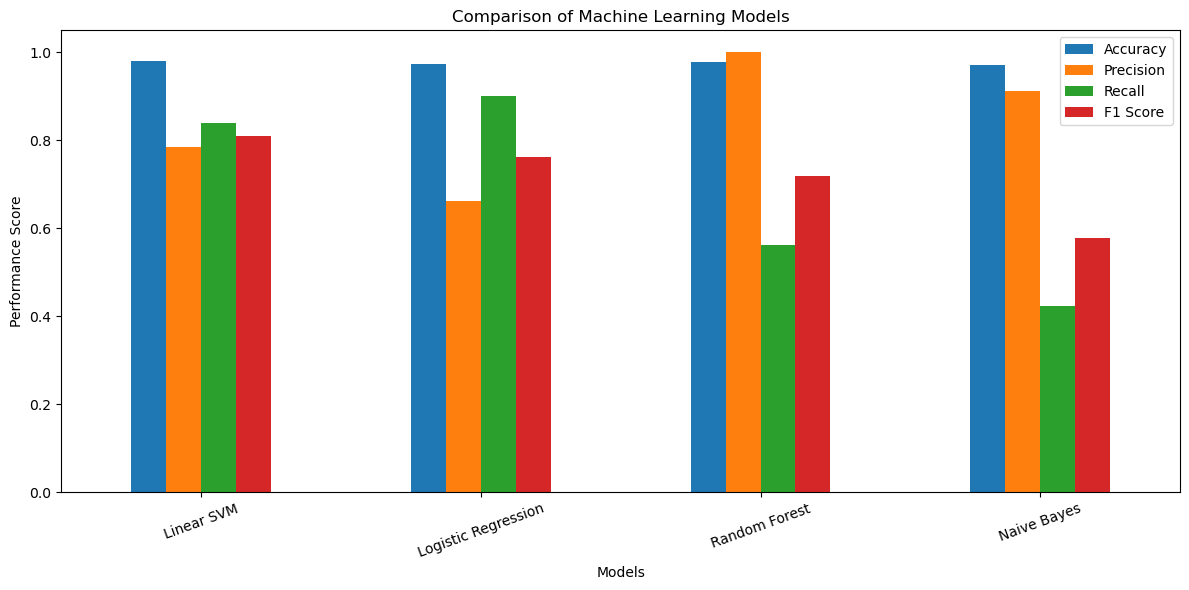


All machine learning models trained successfully!


In [8]:

# TASK 8: Train and Evaluate Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Define machine learning models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=3000
    )
}

results = []
trained_models = {}

# Train and evaluate models
for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4)
    })

    trained_models[name] = model

    print(f"{name} completed!")

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

# Compare model performance
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON:")
display(results_df)

# Visualize model performance
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Performance Score")
plt.xlabel("Models")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("\nAll machine learning models trained successfully!")


In [9]:

# TASK 9: Correct TF-IDF Pipeline (Prevent Data Leakage)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# Separate text and target
X = df["cleaned_text"]
y = df["fraudulent"]

# Split text before fitting TF-IDF
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit TF-IDF only on training text
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=3000
    )
}

results = []
trained_models = {}

# Train and evaluate
for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

print("\nCorrected Model Performance:")
display(results_df.round(4))

print("\nLeakage-free model evaluation completed!")


Training shape: (14304, 5000)
Testing shape: (3576, 5000)

Training Logistic Regression...

Training Naive Bayes...

Training Random Forest...

Training Linear SVM...

Corrected Model Performance:


,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.9810,0.7869,0.8324,0.8090
1,Logistic Regression,0.9723,0.6542,0.9075,0.7603
2,Random Forest,0.9796,1.0000,0.5780,0.7326
3,Naive Bayes,0.9690,0.8780,0.4162,0.5647



Leakage-free model evaluation completed!



Confusion Matrix - Logistic Regression
[[3320   83]
 [  16  157]]


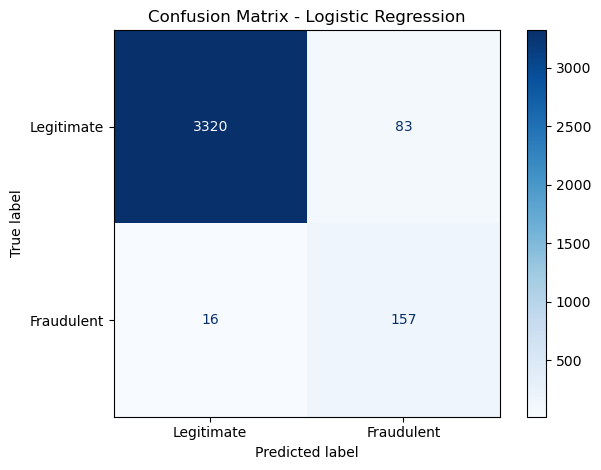


Confusion Matrix - Naive Bayes
[[3393   10]
 [ 101   72]]


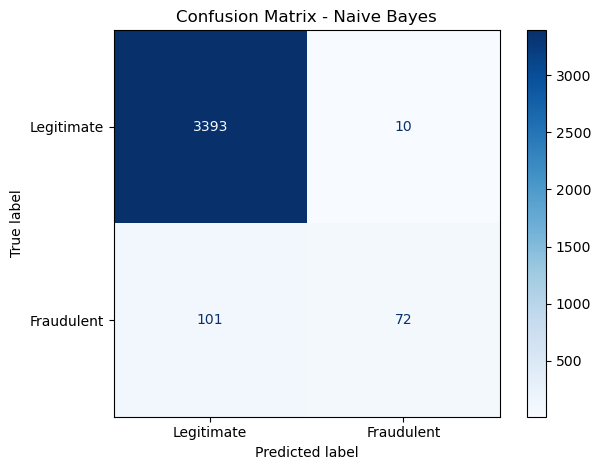


Confusion Matrix - Random Forest
[[3403    0]
 [  73  100]]


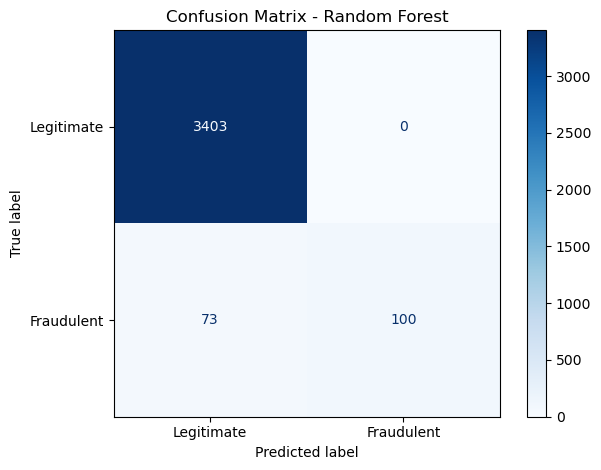


Confusion Matrix - Linear SVM
[[3364   39]
 [  29  144]]


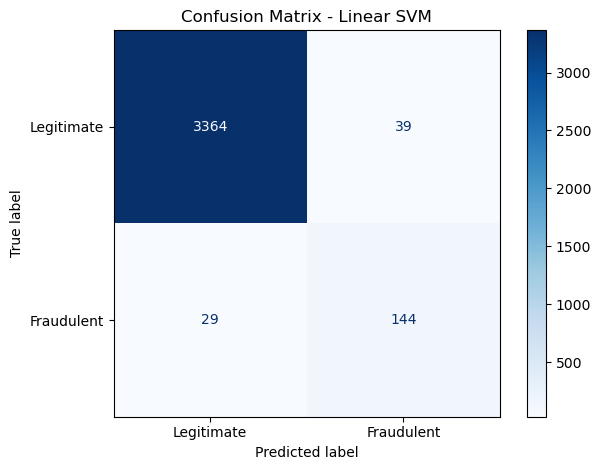


Confusion Matrix Analysis Completed!


In [10]:

# TASK 10: Confusion Matrix Analysis

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in trained_models.items():

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    print(f"\nConfusion Matrix - {name}")
    print(cm)

    # Display confusion matrix
    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraudulent"]
    )

    display_cm.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

print("\nConfusion Matrix Analysis Completed!")


In [11]:

# TASK 12: Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV

print("Starting Logistic Regression tuning...")

# Create parameter combinations
param_grid = {
    "C": [0.1, 1, 5, 10],
    "solver": ["liblinear", "lbfgs"]
}

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Perform tuning
grid_search.fit(X_train, y_train)

# Get best model
best_model = grid_search.best_estimator_

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))

# Evaluate tuned model
tuned_predictions = best_model.predict(X_test)

print("\nTuned Model Performance:")
print("Accuracy:", round(
    accuracy_score(y_test, tuned_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, tuned_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, tuned_predictions, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, tuned_predictions, zero_division=0), 4
))

print("\nHyperparameter tuning completed!")


Starting Logistic Regression tuning...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best Parameters:
{'C': 10, 'solver': 'liblinear'}

Best Cross-Validation F1 Score:
0.765

Tuned Model Performance:
Accuracy: 0.9818
Precision: 0.7784
Recall: 0.8728
F1 Score: 0.8229

Hyperparameter tuning completed!


In [12]:

# TASK 13: Fake Job Posting Prediction System

final_model = best_model

def predict_job_posting(
    title,
    company_profile,
    description,
    requirements,
    benefits
):
    # Combine job information
    job_text = (
        str(title) + " " +
        str(company_profile) + " " +
        str(description) + " " +
        str(requirements) + " " +
        str(benefits)
    )

    # Clean the input text
    cleaned_job = clean_text(job_text)

    # Convert text using the trained TF-IDF vectorizer
    job_vector = tfidf.transform([cleaned_job])

    # Predict job category
    prediction = final_model.predict(job_vector)[0]

    if prediction == 1:
        result = "Fraudulent Job Posting"
    else:
        result = "Legitimate Job Posting"

    print("\nJOB POSTING ANALYSIS")
    print("-------------------------")
    print("Prediction:", result)

    return result


# Test with a sample job posting
sample_result = predict_job_posting(
    title="Work From Home Data Entry",
    company_profile="A company offering remote employment opportunities.",
    description="Earn high income with flexible working hours. "
                "No experience required. Apply immediately.",
    requirements="Basic computer knowledge.",
    benefits="Flexible schedule and attractive earnings."
)

print("\nFinal Result:", sample_result)



JOB POSTING ANALYSIS
-------------------------
Prediction: Fraudulent Job Posting

Final Result: Fraudulent Job Posting


FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Logistic Regression,0.9818,0.7784,0.8728,0.8229
1,Linear SVM,0.9810,0.7869,0.8324,0.8090
2,Logistic Regression,0.9723,0.6542,0.9075,0.7603
3,Random Forest,0.9796,1.0000,0.5780,0.7326
4,Naive Bayes,0.9690,0.8780,0.4162,0.5647


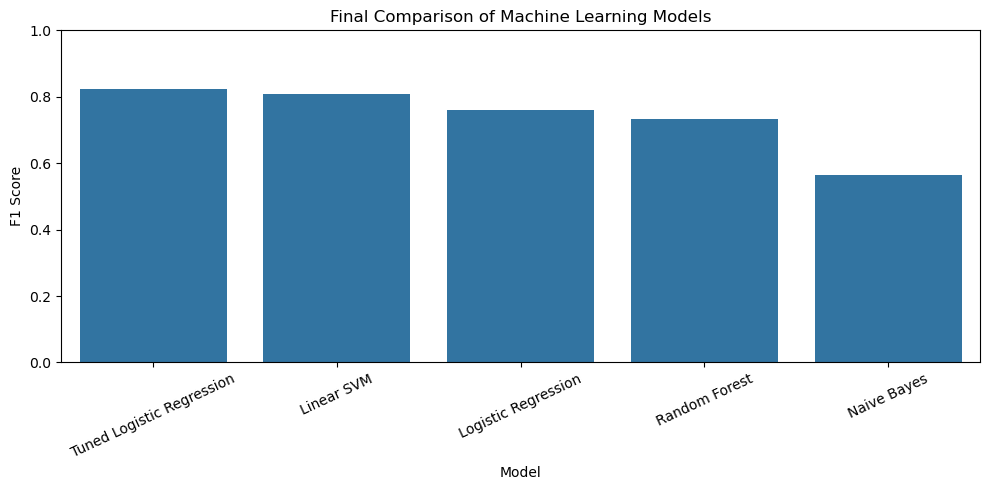

Final model comparison completed!


In [13]:

# TASK 14: Final Model Comparison

# Evaluate tuned Logistic Regression
tuned_results = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(
        y_test, tuned_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, tuned_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, tuned_predictions, zero_division=0
    )
}

# Add tuned model to comparison
final_results = pd.concat(
    [
        results_df,
        pd.DataFrame([tuned_results])
    ],
    ignore_index=True
)

final_results = final_results.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")
display(final_results.round(4))

# Visualize F1 scores
plt.figure(figsize=(10, 5))
sns.barplot(
    data=final_results,
    x="Model",
    y="F1 Score"
)
plt.title("Final Comparison of Machine Learning Models")
plt.xticks(rotation=25)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("Final model comparison completed!")


In [14]:

# TASK 15: Project Conclusion

print("=" * 55)
print("FAKE JOB POSTING DETECTION - PROJECT CONCLUSION")
print("=" * 55)

print("\nDataset Information:")
print("Total Job Postings:", len(df))
print("Total Features:", df.shape[1])

print("\nBest Tuned Model: Logistic Regression")
print("Best Parameters:", grid_search.best_params_)

print("\nFinal Test Performance:")
print(f"Accuracy : {accuracy_score(y_test, tuned_predictions):.4f}")
print(f"Precision: {precision_score(y_test, tuned_predictions, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, tuned_predictions, zero_division=0):.4f}")
print(f"F1 Score : {f1_score(y_test, tuned_predictions, zero_division=0):.4f}")

print("\nProject Conclusion:")
print(
    "This project developed a machine learning system to detect "
    "fraudulent job postings using job-related textual information. "
    "Text cleaning and TF-IDF were used to prepare the data. "
    "Multiple classification algorithms were trained and compared. "
    "Logistic Regression was tuned using GridSearchCV and achieved "
    "promising results. The system can help identify suspicious job "
    "advertisements, although predictions should be reviewed by humans."
)

print("\nPROJECT COMPLETED SUCCESSFULLY!")


FAKE JOB POSTING DETECTION - PROJECT CONCLUSION

Dataset Information:
Total Job Postings: 17880
Total Features: 21

Best Tuned Model: Logistic Regression
Best Parameters: {'C': 10, 'solver': 'liblinear'}

Final Test Performance:
Accuracy : 0.9818
Precision: 0.7784
Recall   : 0.8728
F1 Score : 0.8229

Project Conclusion:
This project developed a machine learning system to detect fraudulent job postings using job-related textual information. Text cleaning and TF-IDF were used to prepare the data. Multiple classification algorithms were trained and compared. Logistic Regression was tuned using GridSearchCV and achieved promising results. The system can help identify suspicious job advertisements, although predictions should be reviewed by humans.

PROJECT COMPLETED SUCCESSFULLY!
